# Neighbourhood NDVI Maps

## 1. Import Libraries

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import contextily as cx
from shapely import box
import requests
from pystac_client import Client
import rioxarray as rxr
import xarray as xr
from shapely.geometry import shape

## 2. Set Output Paths

In [2]:
map_export_path = Path('../web/maps')
map_export_path.mkdir(parents=True, exist_ok=True)

image_export_path = Path('../web/images')
image_export_path.mkdir(parents=True, exist_ok=True)

## 3. Fetch Municipality Boundaries

In [3]:
url = "https://api.pdok.nl/kadaster/brk-bestuurlijke-gebieden/ogc/v1/collections/gemeentegebied/items?f=json"
features = []

while url:
    
    req = requests.get(url)
    req.raise_for_status()

    res = req.json()

    features.extend(res['features'])
    
    next_urls = [
        a['href']
        for a in res['links']
        if a['rel']=='next'
    ]

    url = next_urls[0] if next_urls else None

cities = gpd.GeoDataFrame.from_features(features, crs='EPSG:4326')
cities.head()

,geometry,code,identificatie,ligt_in_provincie_code,ligt_in_provincie_naam,naam
0,"MULTIPOLYGON (((5.26613 51.7393, 5.26704 51.73...",0263,GM0263,25,Gelderland,Maasdriel
1,"MULTIPOLYGON (((4.71723 52.70422, 4.7174 52.70...",0441,GM0441,27,Noord-Holland,Schagen
2,"MULTIPOLYGON (((5.69601 50.75503, 5.69661 50.7...",1903,GM1903,31,Limburg,Eijsden-Margraten
3,"MULTIPOLYGON (((6.10191 52.46469, 6.10193 52.4...",0193,GM0193,23,Overijssel,Zwolle
4,"MULTIPOLYGON (((5.85719 51.02854, 5.85921 51.0...",1711,GM1711,31,Limburg,Echt-Susteren


## 4. Fetch Neighbourhood Boundaries

In [4]:
url = "https://api.pdok.nl/cbs/wijken-en-buurten-2026/ogc/v1/collections/buurten/items?f=json"
features = []

while url:

    req = requests.get(url)
    req.raise_for_status()

    res = req.json()

    features.extend(res['features'])

    next_urls = [
        a['href']
        for a in res['links']
        if a['rel']=='next'
    ]

    url = next_urls[0] if next_urls else None

n_hoods = gpd.GeoDataFrame.from_features(features, crs='EPSG:4326')
n_hoods.head()

,geometry,bu_code,bu_naam,gm_code,gm_naam,jaar,jrgm,jrstatcode,jrwk,water,wk_code,wk_naam
0,"MULTIPOLYGON Z (((6.56757 53.22222 0, 6.5684 5...",BU00140000,Binnenstad-Noord,GM0014,Groningen,2026,2026GM0014,2026BU00140000,2026WK001400,NEE,WK001400,Centrum
1,"MULTIPOLYGON Z (((6.56893 53.21835 0, 6.56952 ...",BU00140001,Binnenstad-Zuid,GM0014,Groningen,2026,2026GM0014,2026BU00140001,2026WK001400,NEE,WK001400,Centrum
2,"MULTIPOLYGON Z (((6.57004 53.22351 0, 6.57417 ...",BU00140002,Binnenstad-Oost,GM0014,Groningen,2026,2026GM0014,2026BU00140002,2026WK001400,NEE,WK001400,Centrum
3,"MULTIPOLYGON Z (((6.55776 53.21876 0, 6.55821 ...",BU00140003,Binnenstad-West,GM0014,Groningen,2026,2026GM0014,2026BU00140003,2026WK001400,NEE,WK001400,Centrum
4,"MULTIPOLYGON Z (((6.56086 53.22668 0, 6.56121 ...",BU00140004,Noorderplantsoen,GM0014,Groningen,2026,2026GM0014,2026BU00140004,2026WK001400,NEE,WK001400,Centrum


## 5. Data Cleaning

In [5]:
names = ['enschede', 'zwolle', 'almelo']

city = {}
n_hood = {}

for name in names:
    city[name] = cities.loc[
        cities['naam']==name.title(),
        ['naam', 'geometry']
    ]

    city[name] = city[name].rename(columns={'naam': 'name'})

    n_hood[name] = n_hoods.loc[
        n_hoods['gm_naam']==name.title(),
        ['bu_naam', 'geometry']
    ]

    n_hood[name] = n_hood[name].rename(columns={'bu_naam': 'name'})

## 6. Calculate Neighbourhood NDVI

In [6]:
for name in names:
    
    print(f'{name.title()}:\n\n')
    
    client = Client.open("https://earth-search.aws.element84.com/v1")
    
    city_geometry = city[name].to_crs('EPSG:4326').geometry.iloc[0]
        
    items = list(client.search(
        collections='sentinel-2-l2a',
        intersects=city_geometry,
        datetime='2026-06-01/2026-08-31',
        query=['eo:cloud_cover<5']
    ).items())

    matching_items = [
        candidate
        for candidate in items
        if shape(candidate.geometry).contains(city_geometry)
    ]

    item = matching_items[0]

    print('Finished Sentinel search')
    
    red = rxr.open_rasterio(
        item.assets['red'].href,
        masked=True
    ).squeeze(dim='band')
    
    nir = rxr.open_rasterio(
        item.assets['nir'].href,
        masked=True
    ).squeeze(dim='band')

    print('Loaded Red and NIR bands')
    
    ndvi = (nir - red) / (nir + red)
    
    ndvi = ndvi.rio.clip(
        city[name].geometry.tolist(),
        city[name].crs
    )

    print('Calculated NDVI')

    mean_ndvi = []
    
    for row in n_hood[name].itertuples():
        n_hood_ndvi = ndvi.rio.clip(
            [row.geometry],
            crs=n_hood[name].crs
        )

        mean_ndvi.append(n_hood_ndvi.mean(skipna=True).item())

    n_hood[name]['mean_ndvi'] = mean_ndvi

    print('Calculated per neighbourhood NDVI\n')

Enschede:


Finished Sentinel search
Loaded Red and NIR bands
Calculated NDVI
Calculated per neighbourhood NDVI

Zwolle:


Finished Sentinel search
Loaded Red and NIR bands
Calculated NDVI
Calculated per neighbourhood NDVI

Almelo:


Finished Sentinel search
Loaded Red and NIR bands
Calculated NDVI
Calculated per neighbourhood NDVI



## 7. Export Folium Maps

In [7]:
for name in names:
    
    m = folium.Map()
    
    folium.Choropleth(
        geo_data=n_hood[name],
        data=n_hood[name]['mean_ndvi'],
        key_on='feature.id',
        fill_color='RdYlGn',
        bins=3,
        legend_name='Mean NDVI'
    ).add_to(m)
    
    g = folium.GeoJson(
        data=n_hood[name],
        zoom_on_click=True,
        style_function=lambda feature:{
            'fillOpacity': 0,
            'weight': 0
        },
        highlight_function=lambda feature:{
            'fillColor': 'black',
            'fillOpacity': 0.2,
            'color': 'black',
            'weight': 1
        },
        tooltip=folium.GeoJsonTooltip(
            fields=['name', 'mean_ndvi'],
            aliases=['Neighbourhood', 'Mean NDVI'],
            localize=True
        )
        
    ).add_to(m)
    
    m.fit_bounds(g.get_bounds())
    m.save(map_export_path / f'{name}.html')

    print(f'Saved map to {map_export_path}/{name}.html')

Saved map to ../web/maps/enschede.html
Saved map to ../web/maps/zwolle.html
Saved map to ../web/maps/almelo.html


## 8. Export Satellite Basemaps

Saved figure to ../web/images/enschede.png
Saved figure to ../web/images/zwolle.png
Saved figure to ../web/images/almelo.png


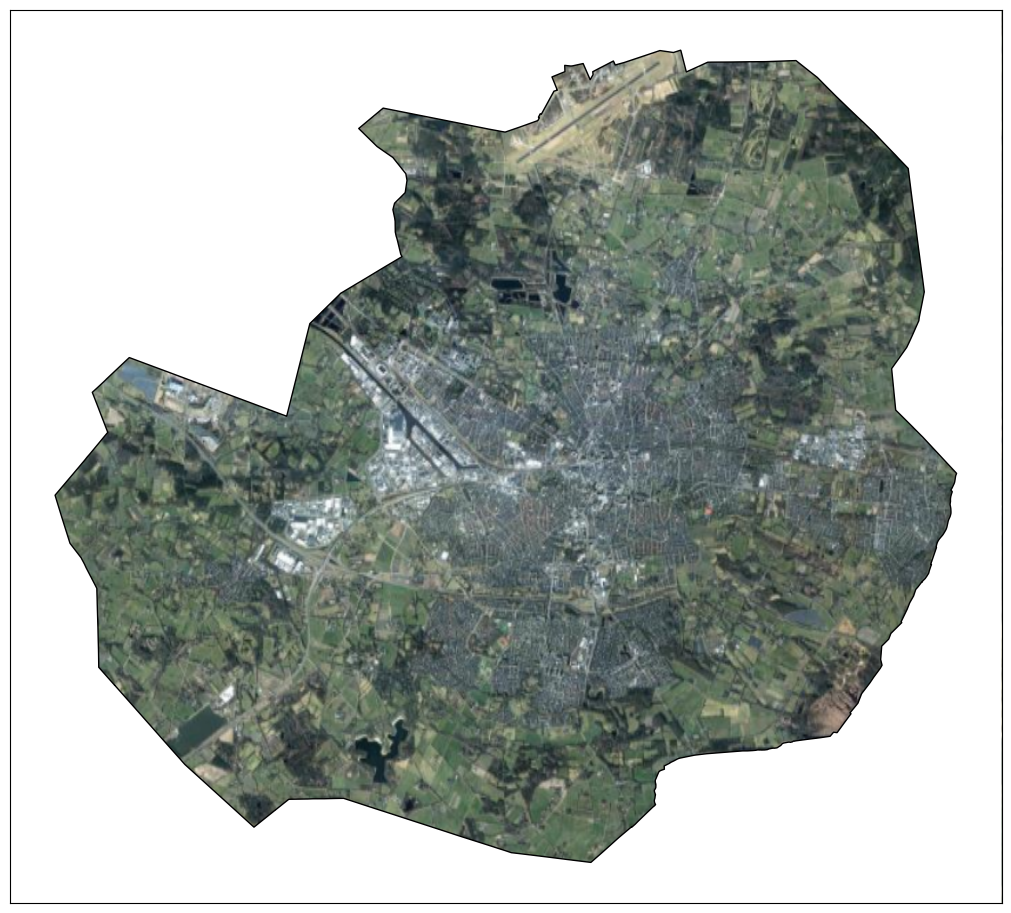

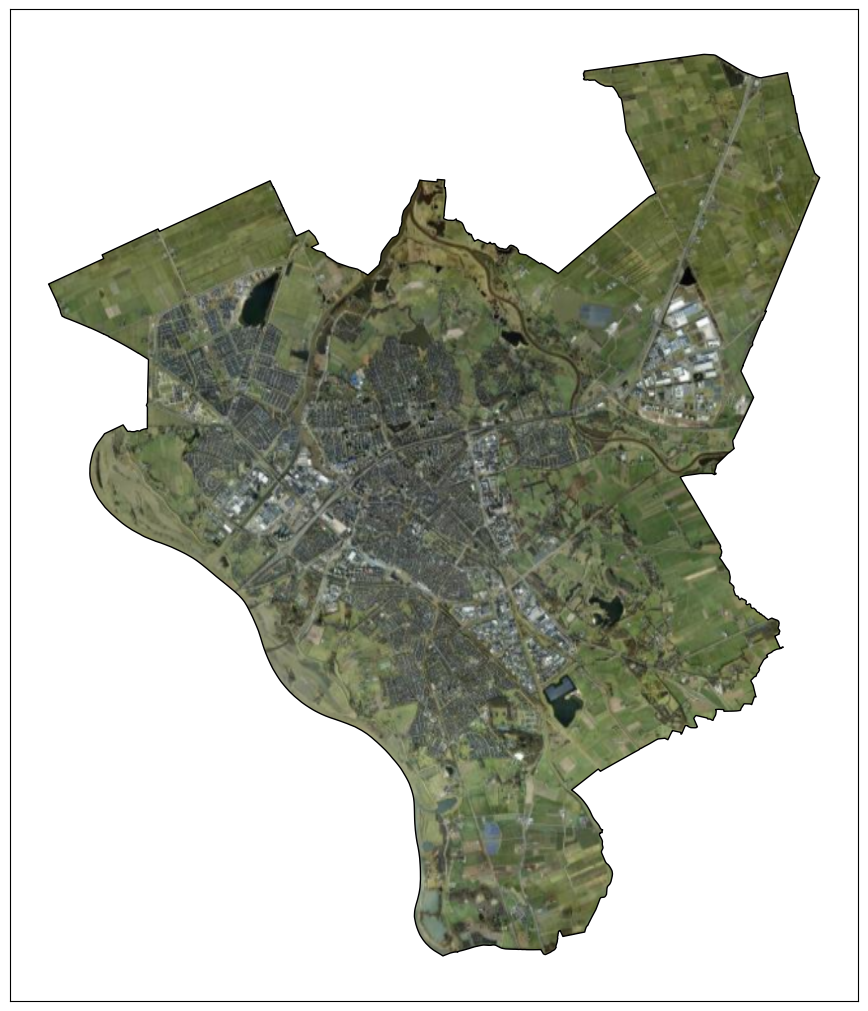

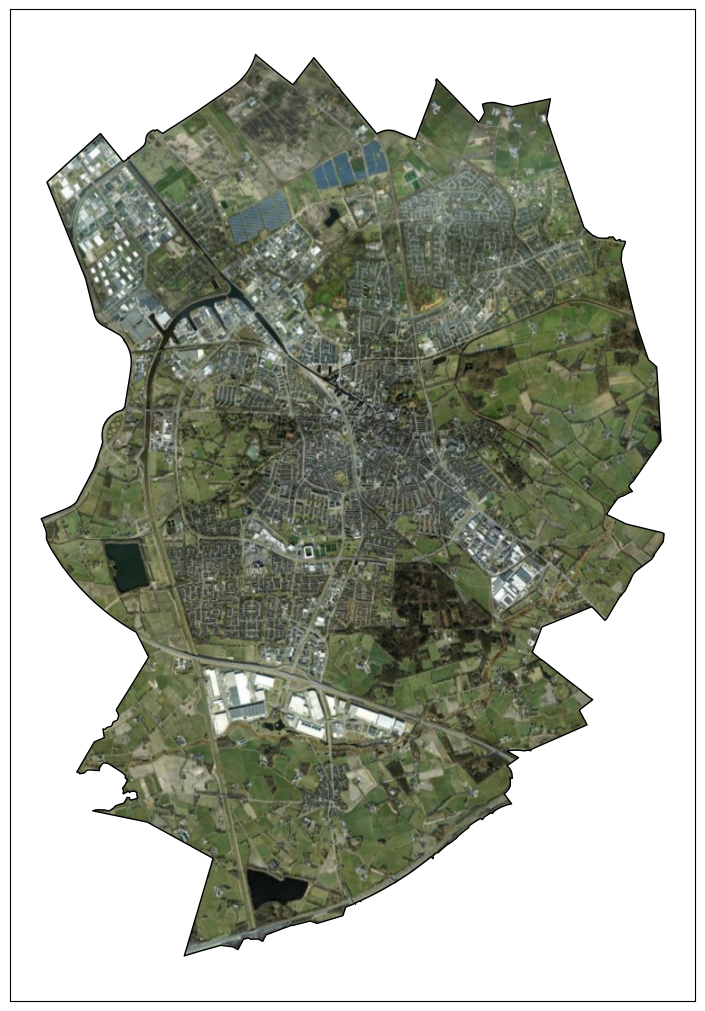

In [8]:
for name in names:
    
    fig, ax = plt.subplots(
        figsize=(10,10),
        constrained_layout=True
    )
    
    city[name].plot(
        ax=ax,
        alpha=0
    )
    
    cx.add_basemap(
        ax=ax,
        crs=city[name].crs,
        source=cx.providers.Esri.WorldImagery,
        attribution=''
    )
    
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    
    box_plot = box(xmin, ymin, xmax, ymax)
    inverse_plot = box_plot.difference(city[name].geometry)
    
    inverse_plot.plot(
        ax=ax,
        color='white'
    )
    
    city[name].plot(
        ax=ax,
        color='none',
        edgecolor='black',
        linewidth=1
    )
    
    ax.set(
        title='',
        xlabel='',
        ylabel='',
        xticks=[],
        yticks=[]
    )

    plt.savefig(
        image_export_path / f'{name}.png',
        dpi=300,
        bbox_inches='tight'
    )

    print(f'Saved figure to {image_export_path}/{name}.png')